# Tutorial 5. A municipal water supply: pump station, rising main and elevated tank

![A municipal water supply](../tutorials/images/t05_hero.png)

**Scope:** hydraulics, civil engineering. **Components:** `Tank`, `Pump`,
`Filter`, `Pipe`, `FluidInertance`, `Orifice`, `FlowSource`, `PressureSource`,
`Atmosphere`.

## The asset

A small town is supplied from a raw-water reservoir through a pump station, a
filter, and a 1.2 km rising main up to an elevated tank 30 m above the pumps.
Consumers draw from the tank; the tank smooths the difference between the pump
and the demand. The reservoir is fed from a river intake. The utility asks:

- **Does the tank hold?** Over a day with a morning and an evening peak, does
  the elevated tank stay within its working band?
- **The filter is fouling.** How much does a half-fouled filter cut the pump flow,
  and when does the tank start to lose the evening peak?
- **A leak.** A 2 cm² hole at the base of the elevated tank: how much water does it
  waste in a day, and would the level trace show it?

![P&ID](../tutorials/images/t05_pd.png)

ISA-5.1 symbols: tanks `TK-101` and `TK-102`, pump `P-101`, filter `F-101` (in
the model it sits at the top of the main, before the tower),
valve `HV-101`, the orifice plate `FE-102` and the transmitters we will read.

## Step 1. Build the network

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.hydraulic import (
    Atmosphere,
    Filter,
    FlowSource,
    FluidInertance,
    Orifice,
    Pipe,
    PressureSource,
    Pump,
    Tank,
)

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

RHO_G = 1000.0 * 9.81


def network(fouling=0.0, leak_area=0.0):
    intake = PressureSource(
        RHO_G * 4.0, name="intake"
    )  # the river, 4 m above the reservoir floor
    intake_pipe = Pipe(
        resistance=2.0e5, name="intake_pipe"
    )  # Pa s/m3, laminar for a long gravity line
    intake_column = FluidInertance(
        1000.0 * 800.0 / 0.07, name="intake_column"
    )  # rho L / A of the gravity line
    reservoir = Tank(400.0, level=3.0, name="reservoir")  # m2, m
    pump = Pump(
        shutoff=4.6e5, max_flow=0.13, inertance=1000.0 * 1200.0 / 0.0314, name="pump"
    )  # 47 m shutoff; the main's water column
    sand_filter = Filter(
        1.2e6, fouling=fouling, name="filter"
    )  # Pa s/m3; fouling multiplies it
    main = Pipe(friction=8.0e6, name="main")  # dp = K Q |Q|, 1.2 km of DN200
    tower = Tank(
        300.0, level=2.0, base_elevation=30.0, name="tower"
    )  # m2, m, m above the pumps
    demand = FlowSource(None, name="demand")  # m3/s drawn by the town, an input
    atm = Atmosphere(name="atm")
    parts = [
        intake,
        intake_pipe,
        intake_column,
        reservoir,
        pump,
        sand_filter,
        main,
        tower,
        demand,
        atm,
    ]
    s = otwin.System(*parts)
    s.connect(intake.a, intake_pipe.a)
    s.connect(intake_pipe.b, intake_column.a)
    s.connect(intake_column.b, reservoir.port, pump.inlet)
    s.connect(pump.outlet, main.a)
    s.connect(main.b, sand_filter.a)
    s.connect(sand_filter.b, tower.port, demand.b)
    s.connect(demand.a, intake.b, atm.port)
    if leak_area > 0:
        leak = Orifice(leak_area, discharge_coefficient=0.62, name="leak")
        s.add(leak)
        s.connect(tower.port, leak.a)
        s.connect(leak.b, atm.port)
    return otwin.compile(s)


model = network()
print(model.summary())

System: system

Components:
  intake                       pressure_source [hydraulic]
  intake_pipe                  pipe [hydraulic]
  intake_column                fluid_inertance [hydraulic]
  reservoir                    tank [hydraulic]
  pump.head                    pressure_source [hydraulic]
  pump.curve                   pipe [hydraulic]
  pump.water                   fluid_inertance [hydraulic]
  filter                       filter [hydraulic]
  main                         pipe [hydraulic]
  tower                        tank [hydraulic]
  demand                       flow_source [hydraulic]
  atm                          atmosphere [any]

States:
  intake_column.flow_momentum  flow momentum [Pa s]  x0 = 0
  reservoir.volume             volume [m^3]  x0 = 1200
  pump.water.flow_momentum     flow momentum [Pa s]  x0 = 0
  tower.volume                 volume [m^3]  x0 = 600

Inputs:
  demand                       flow [m^3/s]

Constant sources:
  intake
  pump.head

Parameters:

Four states: the volumes of the two tanks, the momentum of the water in the
intake line, and the pump's flow. A `Pump` carries an inertance of its own, here
set to the water column of the rising main (ρL/A), so the pump and the main share
one flow state: two flow-setting elements in series with only a resistor between
them would leave the node between undetermined, and the compiler refuses that.
The demand is the one input. The `Tank` with `base_elevation=30` puts the tower's water 30 m above the
datum, so the pump sees that head plus the level.

## Step 2. A day of demand

The town draws 60 L/s on average, with a morning peak at 07:30 and an evening
peak at 20:00. Run 48 hours so the first day settles and the second is the one
we read.

In [ ]:
t = np.arange(0, 48 * 3600 + 1, 10.0)


def town(time):
    h = (time / 3600) % 24
    peaks = 0.055 * np.exp(-((h - 7.5) ** 2) / 1.5) + 0.065 * np.exp(
        -((h - 20.0) ** 2) / 3.0
    )
    return 0.035 + peaks  # m3/s


run = model.simulate(t=t, inputs={"demand": town})
day2 = t >= 24 * 3600
level = run["tower.level"]
print(
    f"pump flow: {run['pump.flow'][day2].min() * 1e3:.0f} to {run['pump.flow'][day2].max() * 1e3:.0f} L/s; "
    f"demand {min(town(x) for x in t) * 1e3:.0f} to {max(town(x) for x in t) * 1e3:.0f} L/s"
)
print(
    f"tower level on day 2: {level[day2].min():.2f} to {level[day2].max():.2f} m "
    f"(working band 2.0 to 6.0 m)"
)
print(
    f"pump head {run['pump.pressure_rise'][day2].mean() / RHO_G:.1f} m, "
    f"friction loss in the main {run['main.pressure'][day2].mean() / RHO_G:.1f} m, filter {run['filter.pressure'][day2].mean() / RHO_G:.1f} m"
)
print(
    f"reservoir level {run['reservoir.level'][-1]:.2f} m: the intake keeps up with the pump"
)

pump flow: 49 to 53 L/s; demand 35 to 100 L/s
tower level on day 2: 3.35 to 5.24 m (working band 2.0 to 6.0 m)
pump head 39.7 m, friction loss in the main 2.1 m, filter 6.2 m
reservoir level 2.95 m: the intake keeps up with the pump


The pump works on its curve: when the tower is low the head is lower and the
pump delivers more, so the system is self-regulating and the level stays in the
band. The head breakdown is the engineer's check: static lift, friction in the
main, and the filter, together equal the pump head.

## Step 3. Plot the day

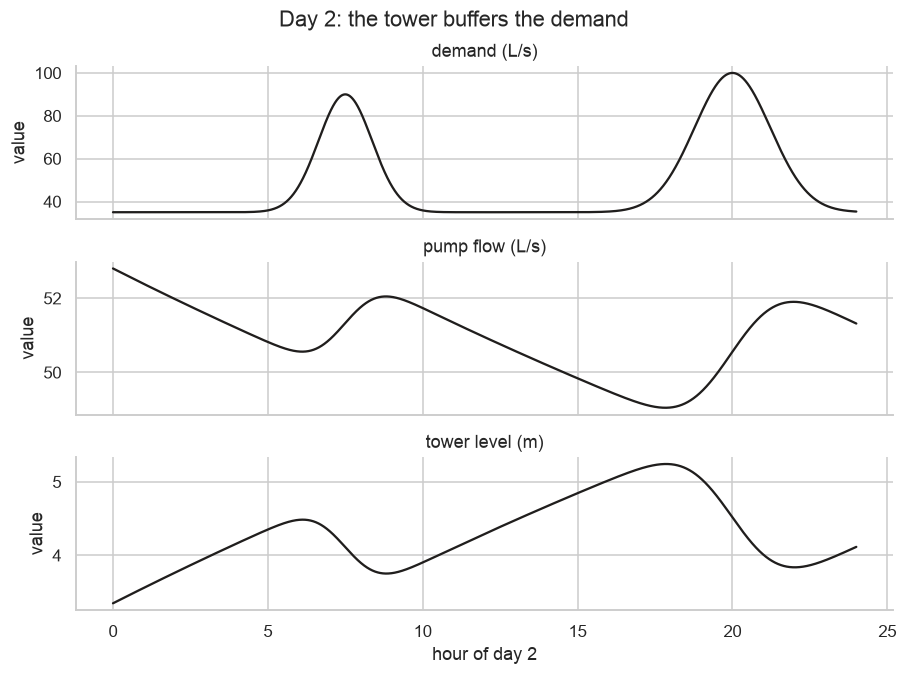

In [ ]:
hours = t / 3600 - 24
frame = pd.DataFrame(
    {
        "hour of day 2": hours[day2],
        "demand (L/s)": run["demand"][day2] * 1e3,
        "pump flow (L/s)": run["pump.flow"][day2] * 1e3,
        "tower level (m)": level[day2],
    }
)
long = frame.melt("hour of day 2", var_name="signal", value_name="value")
g = sns.relplot(
    data=long,
    x="hour of day 2",
    y="value",
    row="signal",
    kind="line",
    height=2.0,
    aspect=4.2,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.figure.suptitle("Day 2: the tower buffers the demand", y=1.02)

The pump flow barely moves while the demand swings by a factor of three; the
difference is what the tower level does. That is what an elevated tank is for.

## Step 4. Fouling and a leak

Run the same day with a half-fouled filter, and separately with a 2 cm² leak at
the base of the tower.

In [ ]:
cases = {
    "as designed": network(),
    "filter half fouled": network(fouling=0.5),
    "2 cm2 leak": network(leak_area=2e-4),
}
rows, traces = [], []
for label, m in cases.items():
    out = m.simulate(t=t, inputs={"demand": town})
    leak = out["leak.flow"] if "leak.flow" in m.output_names else np.zeros(t.size)
    rows.append(
        {
            "case": label,
            "min tower level day 2 (m)": out["tower.level"][day2].min(),
            "mean pump flow (L/s)": out["pump.flow"][day2].mean() * 1e3,
            "water lost per day (m3)": np.trapezoid(leak[day2], t[day2]),
        }
    )
    traces.append(
        pd.DataFrame(
            {
                "hour of day 2": hours[day2],
                "tower level (m)": out["tower.level"][day2],
                "case": label,
            }
        )
    )
print(pd.DataFrame(rows).round(2).to_string(index=False))

              case  min tower level day 2 (m)  mean pump flow (L/s)  water lost per day (m3)
       as designed                       3.35                 50.95                     0.00
filter half fouled                       1.86                 48.41                     0.00
        2 cm2 leak                       2.65                 52.73                   274.16


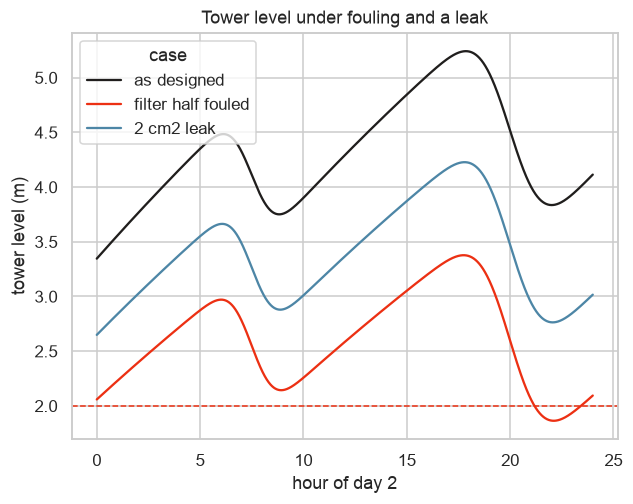

In [ ]:
ax = sns.lineplot(
    data=pd.concat(traces), x="hour of day 2", y="tower level (m)", hue="case"
)
ax.axhline(2.0, color="#EC3013", ls="--", lw=1)
ax.set_title("Tower level under fouling and a leak")

Fouling lowers the pump flow and the whole level trace with it, most visibly at
the evening peak. The leak wastes the volume printed every day and lowers the
level by a roughly constant amount: a leak and fouling look alike on a level
trace, and telling them apart needs the pump flow as well. That is the case for
fitting the model to both measurements, which Tutorial 10 does.

## Step 5. The hand check: Torricelli

An `Orifice` is Torricelli's law, Q = C_d A √(2 Δp / ρ). Check the leak flow
against the closed form. The tank port is 30 m above the atmosphere node, so the
leak discharges at the foot of the riser under the level plus the elevation: a
hole at ground level in the tower's downpipe.

In [ ]:
leaky = cases["2 cm2 leak"]
out = leaky.simulate(t=t, inputs={"demand": town})
head = out["tower.level"][day2].mean() + 30.0
q_model = out["leak.flow"][day2].mean()
q_hand = 0.62 * 2e-4 * np.sqrt(2 * 9.81 * head)
print(
    f"mean head {head:.2f} m: leak flow {q_model * 1e3:.2f} L/s in the model, {q_hand * 1e3:.2f} L/s by hand"
)

mean head 33.38 m: leak flow 3.17 L/s in the model, 3.17 L/s by hand


The orifice law comes out exactly; the small difference is the mean of a square
root against the square root of a mean.

## What to take from this

- A pump line reads like the drawing: tank, pump, filter, main, tank. The compiler
  solves the network at every step, including the pump curve.
- `base_elevation` and `Tank` give static head; `Pipe(friction=)` turbulent loss;
  `FluidInertance` the water column's mass, which matters for surge; a `Pump`
  carries its own.
- Variants (fouling, a leak) are new systems with one line changed, and the same
  demand input drives all of them.

Next: [Tutorial 6](06_wastewater_disinfection.md) adds chemistry to a water
system.